In [140]:
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras.models import Sequential
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np
from keras.preprocessing import image
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelEncoder 
from sklearn.linear_model import LinearRegression 
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingRegressor

con =  pd.read_csv('concrete_data.csv')
con

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


In [141]:
con.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [142]:
con.duplicated().sum()


np.int64(25)

In [143]:
con.drop_duplicates(inplace = True)

<Axes: xlabel='Strength'>

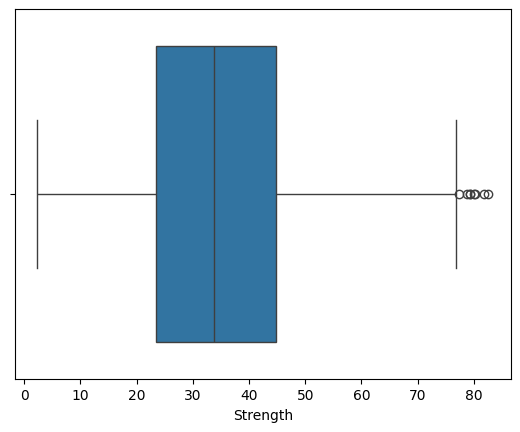

In [144]:
sns.boxplot(x='Strength',data=con)

<Axes: >

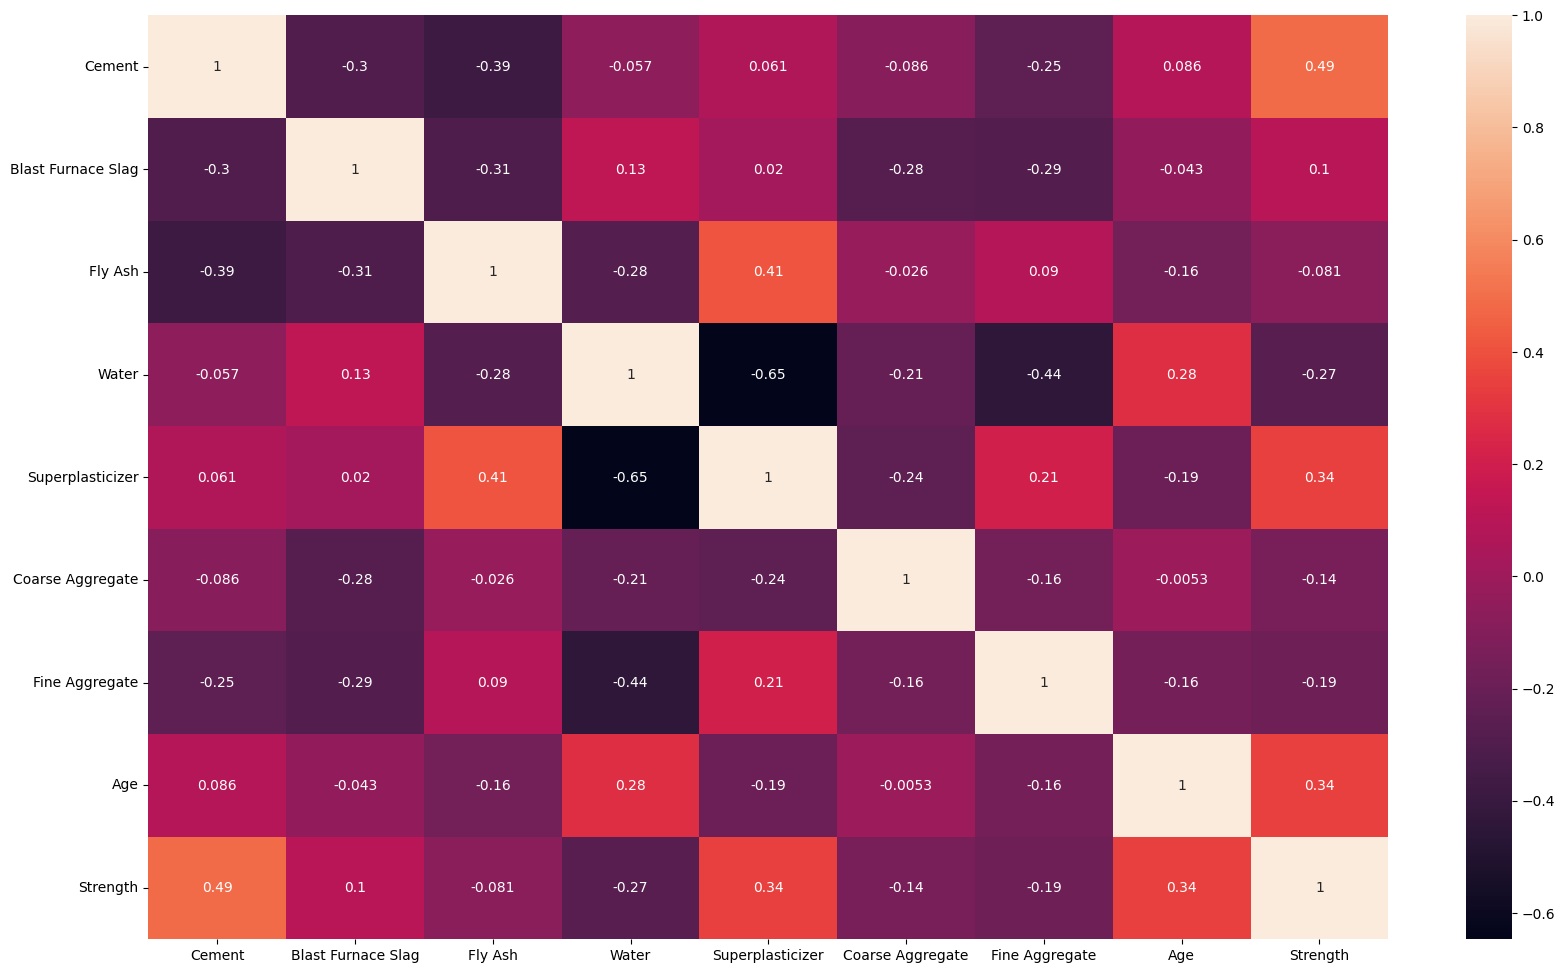

In [145]:
plt.figure(figsize=(20,12))
sns.heatmap(con.select_dtypes(include='number').corr(),annot=True)

In [146]:
from sklearn.preprocessing import LabelEncoder , StandardScaler
x = con.drop('Strength',axis = 1)# independent columns
x
y = con['Strength'] 
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=42)
scaler = StandardScaler()
x= scaler.fit_transform(x)




In [147]:
classifier = Sequential()


In [148]:
classifier.add(Dense(units=8))

In [169]:
classifier.add(Dense(units=60,activation='relu')) 
classifier.add(Dense(units=80,activation='relu'))
classifier.add(Dense(units=90,activation='relu')) 
classifier.add(Dense(units=100,activation='relu'))


In [172]:
classifier.add(Dense(units=1, activation='linear'))

In [173]:
classifier.compile(optimizer="adam",loss="mse",metrics=['mse'])

In [174]:
model_history= classifier.fit(x_train,y_train,validation_split=0.33,batch_size=100,epochs=400)

Epoch 1/400
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 123ms/step - loss: 1481.5046 - mse: 1481.5046 - val_loss: 1301.2256 - val_mse: 1301.2256
Epoch 2/400
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 1184.0674 - mse: 1184.0674 - val_loss: 662.7637 - val_mse: 662.7637
Epoch 3/400
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - loss: 431.7792 - mse: 431.7792 - val_loss: 519.8686 - val_mse: 519.8686
Epoch 4/400
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 367.3255 - mse: 367.3255 - val_loss: 251.5060 - val_mse: 251.5060
Epoch 5/400
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 315.4723 - mse: 315.4723 - val_loss: 268.8089 - val_mse: 268.8089
Epoch 6/400
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 253.6983 - mse: 253.6983 - val_loss: 257.4576 - val_mse: 257.4576
Epoch 7/400
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 266.6621 - mse: 266.6621 - val_loss: 215.6326 - val_mse: 215.6326
Epoch 8/400
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 232.7877 - mse: 232.7877 - val_loss: 212.3819 - val_mse: 212.3819


In [177]:
y_pred = classifier.predict(x_train)

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


In [178]:
mse= mean_squared_error(y_train,y_pred)
mse

27.41546587306546

In [179]:
r2score = r2_score(y_train,y_pred)
r2score

0.8930815645971093